# Dataset Description
## Lending rate

**Source**: [Banco de la República](https://suameca.banrep.gov.co/descarga-multiple-de-datos/)

# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [2]:
path = "./data/tasa_colocacion.csv"

df = pd.read_csv(
    path, encoding="utf-8",
    parse_dates=["Fecha"], date_format="%d/%m/%Y", dayfirst=True
)

## Clean data

In [21]:
idx_max = df["Tasa (%)"].idxmax()
max = df.iloc[idx_max]

idx_start = df["Tasa (%)"].idxmin()
date_start = df.loc[idx_start, "Fecha"]
min_value = df.loc[idx_start, "Tasa (%)"]

date_end = df["Fecha"].max()

_2026 = df[df["Fecha"].dt.year.eq(2026)]
final_2026_value = _2026.iloc[-1]["Tasa (%)"]

print(date_start, date_end)

2021-05-31 00:00:00 2026-09-30 00:00:00


## Plot

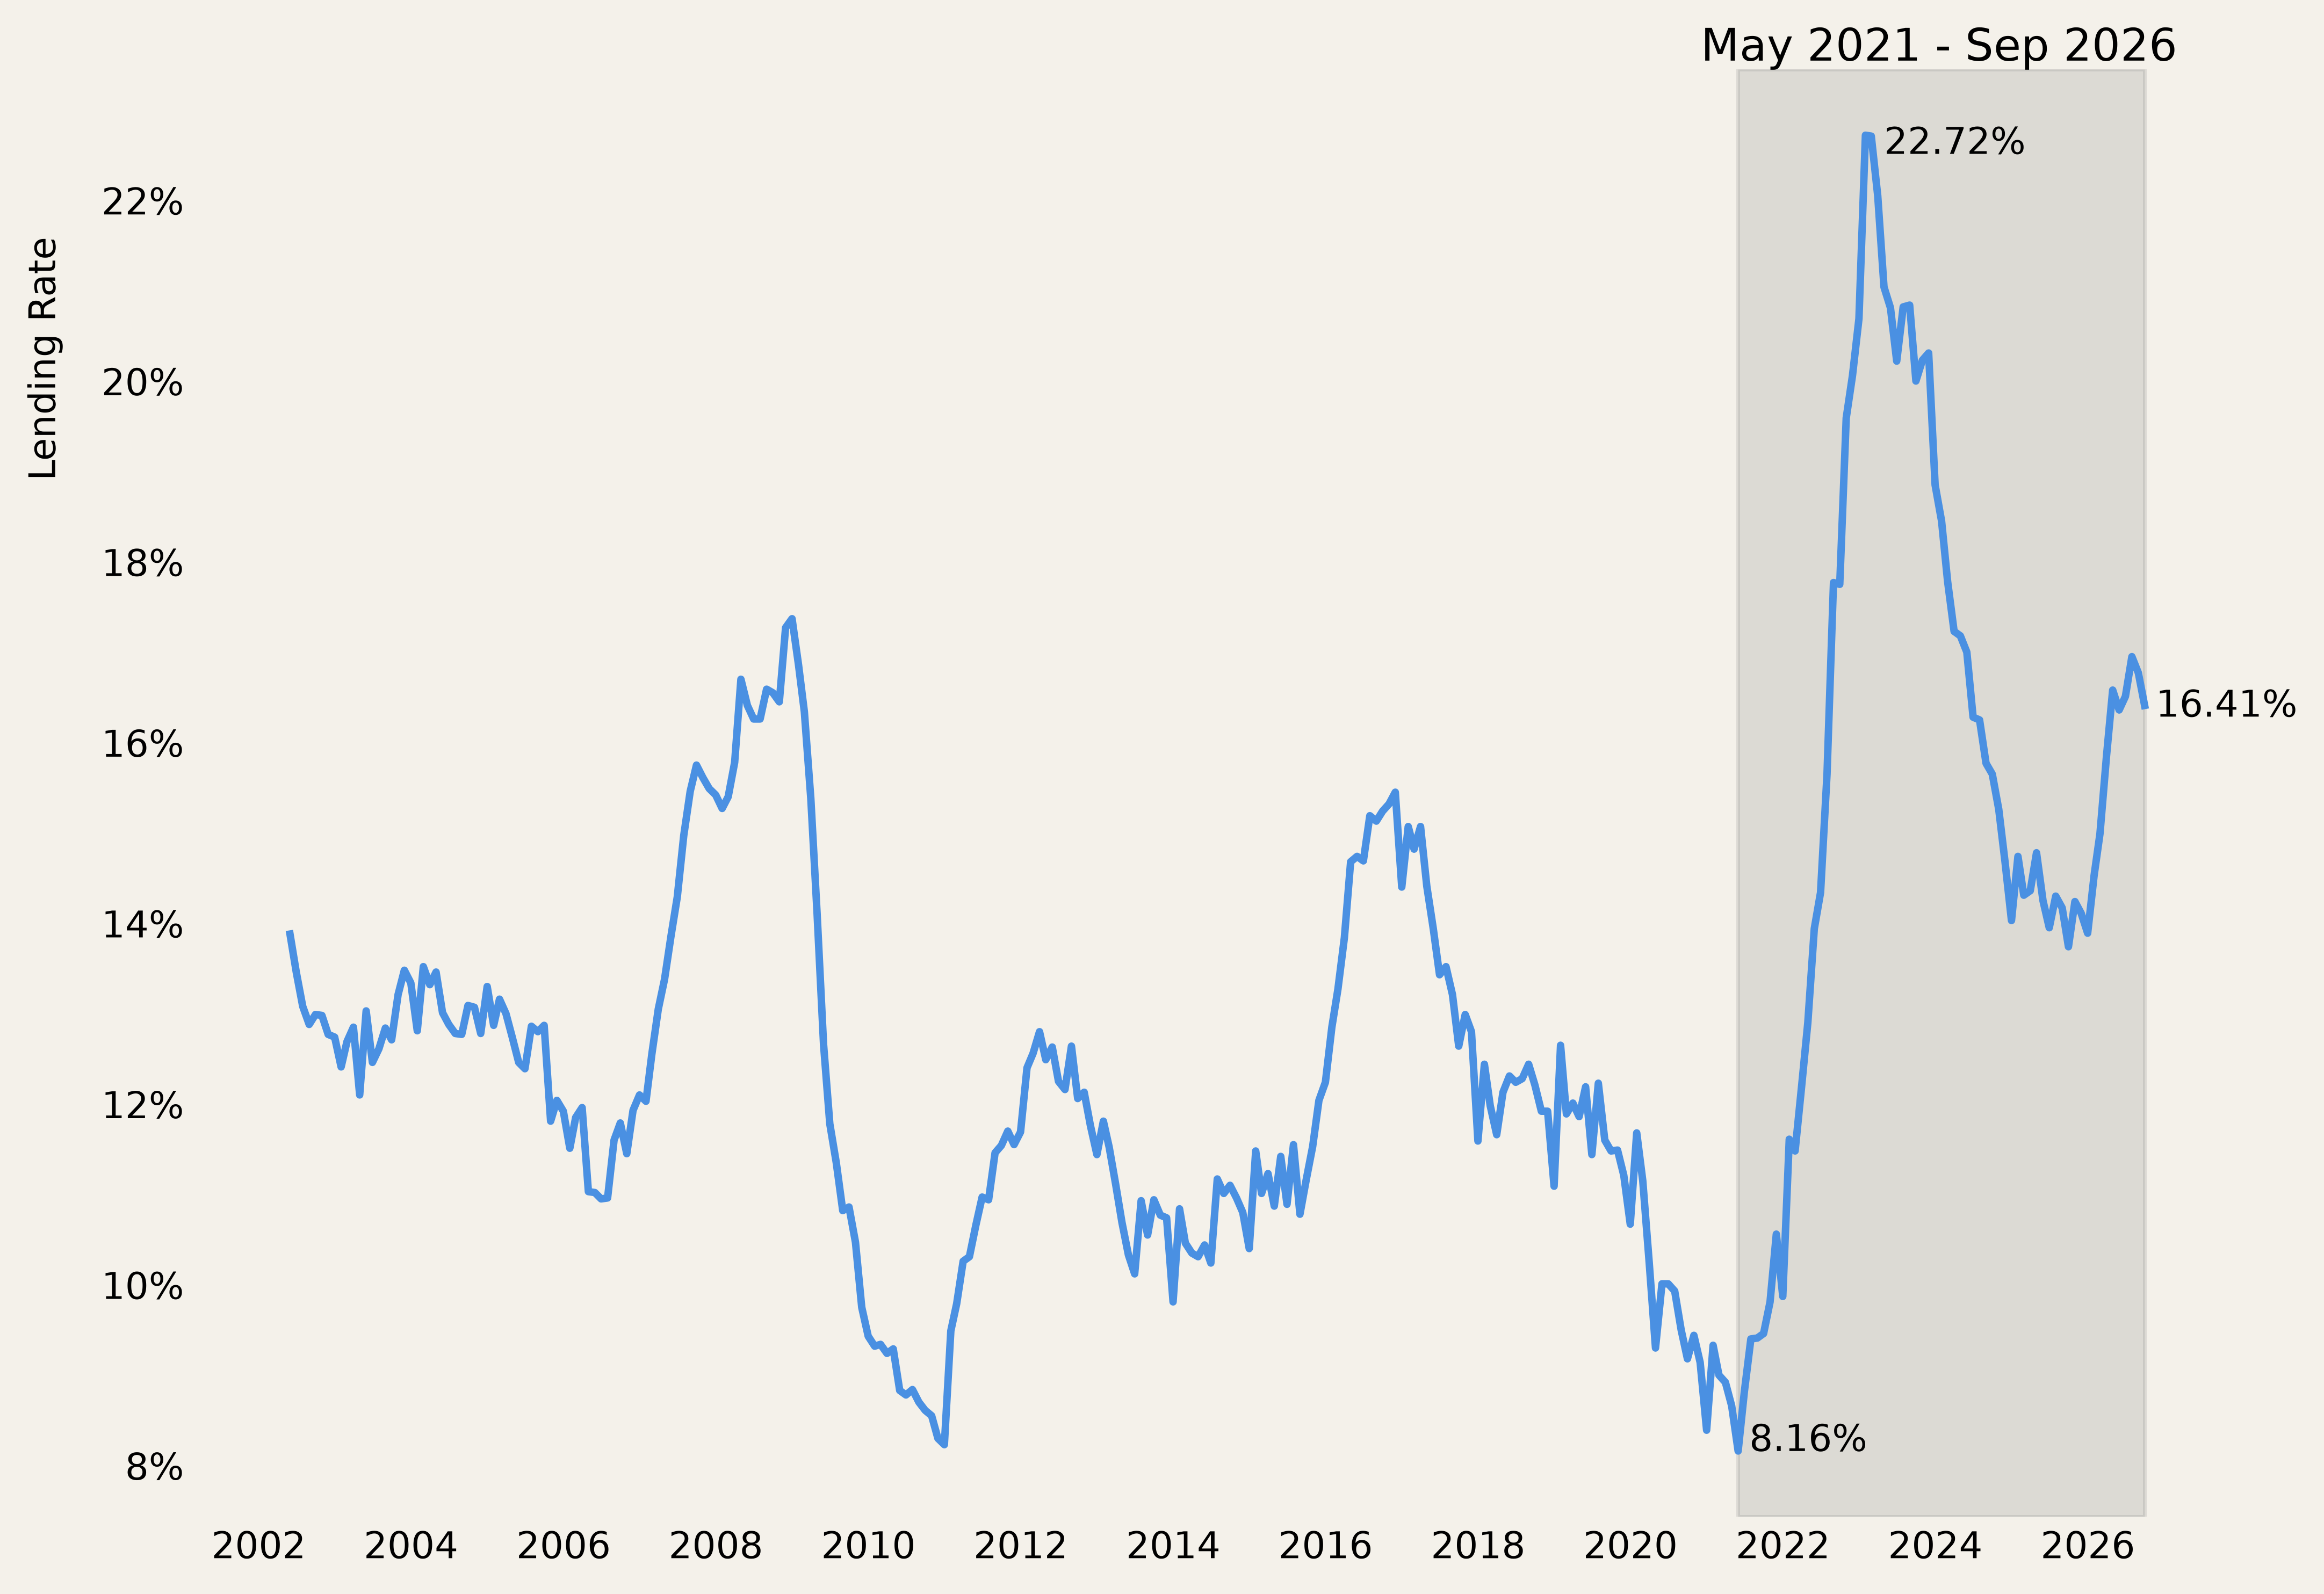

In [40]:
background = "#F4F1EA"
blue = "#4a90e2"

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

plt.plot(df["Fecha"], df["Tasa (%)"], linewidth=2, color=blue)

plt.gca().xaxis.set_major_locator(mdates.YearLocator(base=2, month=1, day=1))

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

plt.ylabel("Lending Rate", fontsize=10, labelpad=10, y=0.8)

plt.axvspan(date_start, date_end, color="gray", alpha=0.2)

plt.annotate(
    "May 2021 - Sep 2026",
    xy=(date_start, max["Tasa (%)"]),
    xytext=(-10,20),
    textcoords="offset points",
    ha="left",
    fontsize=12
)

plt.annotate(
    f"{min_value}%",
    xy=(date_start, min_value),
    xytext=(3,0),
    textcoords="offset points"
)

plt.annotate(
    f"{final_2026_value}%",
    xy=(date_end, final_2026_value),
    xytext=(3,-3),
    textcoords="offset points"
)

plt.annotate(
    f"{max["Tasa (%)"]}%",
    xy=(max["Fecha"],max["Tasa (%)"]),
    xytext=(5,-5),
    textcoords="offset points",
    fontsize=10
)

plt.show()